In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
max_features = 10000
max_len = 200

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=max_features)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=max_len)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test, maxlen=max_len)

In [5]:
class_names = ['Negative', 'Positive']

In [6]:
rnn_model = models.Sequential()

In [7]:
rnn_model.add(layers.Embedding(input_dim=max_features, output_dim=128, input_length=max_len))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [8]:
rnn_model.add(layers.LSTM(64, return_sequences=False))

In [9]:
rnn_model.add(layers.Dropout(0.5))

In [10]:
rnn_model.add(layers.Dense(1, activation='sigmoid'))

In [11]:
rnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [12]:
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = rnn_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=2
)

Epoch 1/10
313/313 - 83s - 267ms/step - accuracy: 0.7721 - loss: 0.4670 - val_accuracy: 0.8706 - val_loss: 0.3177
Epoch 2/10
313/313 - 81s - 259ms/step - accuracy: 0.9013 - loss: 0.2526 - val_accuracy: 0.8712 - val_loss: 0.3103
Epoch 3/10
313/313 - 81s - 259ms/step - accuracy: 0.9294 - loss: 0.1905 - val_accuracy: 0.8680 - val_loss: 0.3247
Epoch 4/10
313/313 - 90s - 289ms/step - accuracy: 0.9482 - loss: 0.1438 - val_accuracy: 0.8558 - val_loss: 0.3550
Epoch 5/10
313/313 - 133s - 423ms/step - accuracy: 0.9396 - loss: 0.1564 - val_accuracy: 0.8562 - val_loss: 0.3933
Epoch 6/10
313/313 - 82s - 261ms/step - accuracy: 0.9685 - loss: 0.0945 - val_accuracy: 0.8710 - val_loss: 0.4688
Epoch 7/10
313/313 - 81s - 259ms/step - accuracy: 0.9742 - loss: 0.0761 - val_accuracy: 0.8636 - val_loss: 0.4937
Epoch 8/10
313/313 - 82s - 262ms/step - accuracy: 0.9778 - loss: 0.0679 - val_accuracy: 0.8618 - val_loss: 0.6005
Epoch 9/10
313/313 - 86s - 274ms/step - accuracy: 0.9821 - loss: 0.0563 - val_accuracy:

In [14]:
test_loss, test_acc = rnn_model.evaluate(x_test, y_test, verbose=2)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")

782/782 - 25s - 32ms/step - accuracy: 0.8260 - loss: 0.7000

Final Test Accuracy: 82.60%


In [15]:
y_pred_probs = rnn_model.predict(x_test)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step


In [16]:
print(classification_report(y_test, y_pred, target_names=class_names))

              precision    recall  f1-score   support

    Negative       0.77      0.92      0.84     12500
    Positive       0.90      0.73      0.81     12500

    accuracy                           0.83     25000
   macro avg       0.84      0.83      0.82     25000
weighted avg       0.84      0.83      0.82     25000



In [17]:
cm = confusion_matrix(y_test, y_pred)

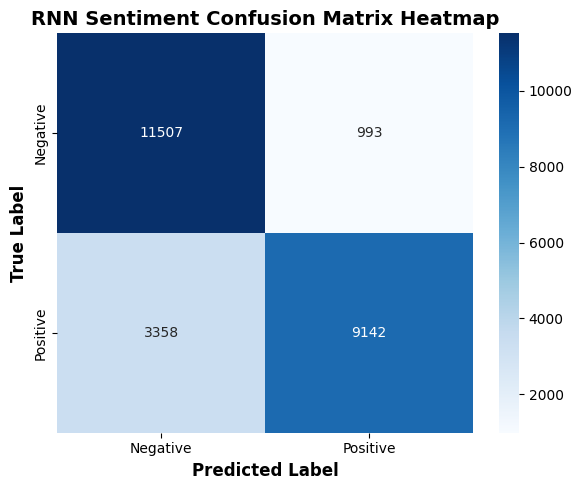

In [18]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('RNN Sentiment Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()